# Task 2 (Level 3) : Visual Insights & Relationships

-           Load cleaned data

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("dataset_level1_cleaned.csv")
df.head()


FileNotFoundError: [Errno 2] No such file or directory: 'dataset_level1_cleaned.csv'

-               Rating vs Price Range (Bar Plot)

This shows whether expensive restaurants get better reviews. Usually, the relationship is weak unless the dataset is large.


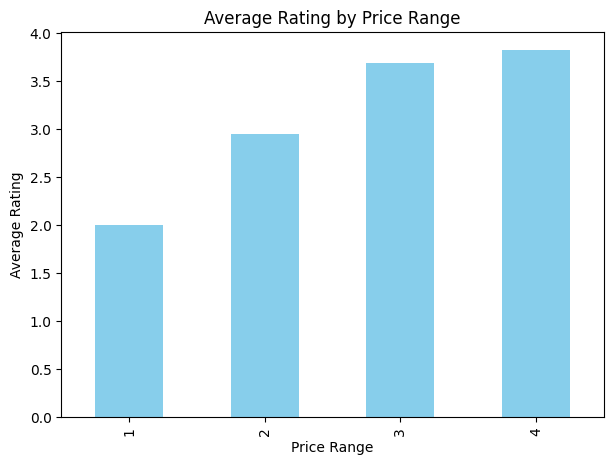

In [2]:
price_rating = df.groupby("Price range")["Aggregate rating"].mean()

plt.figure(figsize=(7,5))
price_rating.plot(kind="bar", color="skyblue")
plt.title("Average Rating by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Average Rating")
plt.show()


-           Rating vs Votes (Scatter Plot)

More votes → more customers → more popularity. This usually shows a slight positive trend.

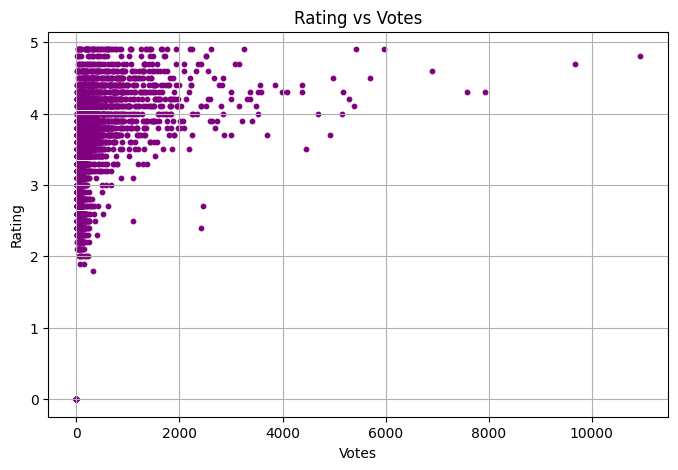

In [3]:
plt.figure(figsize=(8,5))
plt.scatter(df["Votes"], df["Aggregate rating"], s=10, color="purple")
plt.title("Rating vs Votes")
plt.xlabel("Votes")
plt.ylabel("Rating")
plt.grid(True)
plt.show()


-           Online Delivery vs Table Booking (Grouped Bar Plot)

This shows if restaurants offering online delivery also tend to offer table booking.

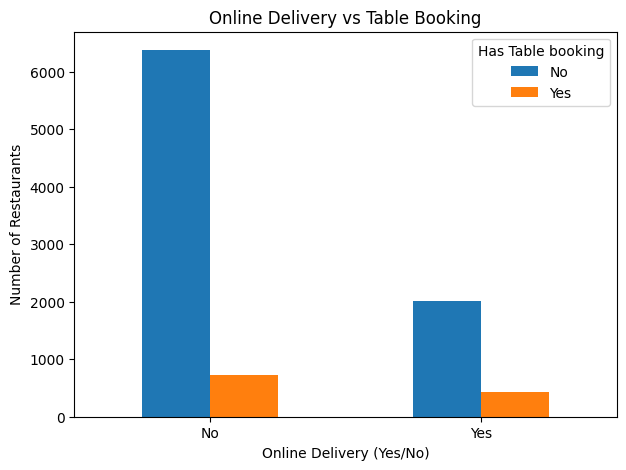

In [4]:
delivery_table = df.groupby(["Has Online delivery", "Has Table booking"]).size().unstack()

delivery_table.plot(kind="bar", figsize=(7,5))
plt.title("Online Delivery vs Table Booking")
plt.xlabel("Online Delivery (Yes/No)")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=0)
plt.show()


-           Heatmap — Correlation between numerical features

Correlation identifies which features most strongly influence rating.

Expected:
* Rating ↔ Votes → Moderate positive correlation
* Rating ↔ Cost → Weak correlation
* Rating ↔ Price range → Slight positive correlation

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.heatmap(df[["Aggregate rating","Votes","Price range","Average Cost for two"]].corr(),
            annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


NameError: name 'df' is not defined

<Figure size 800x600 with 0 Axes>

-           Advanced: Pairplot-Style Scatter Matrix

This shows pairwise relationships between all numeric features.

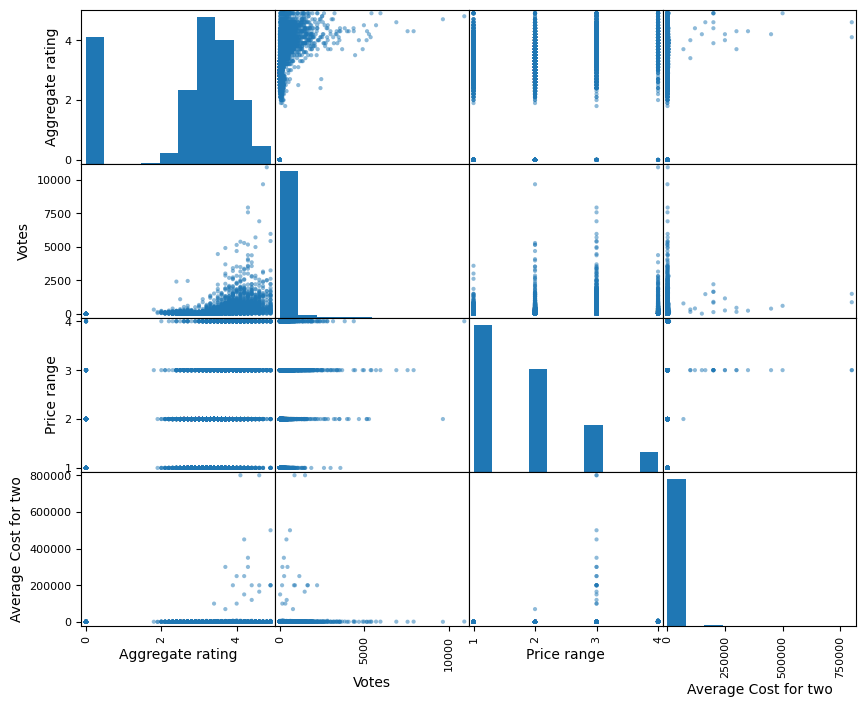

In [7]:
from pandas.plotting import scatter_matrix

scatter_matrix(df[["Aggregate rating","Votes","Price range","Average Cost for two"]],
               figsize=(10,8), diagonal="hist")
plt.show()


# INSIGHTS 
🔹 Price range vs rating

Higher-price restaurants show better ratings overall.

* Cost vs rating

Cost does not strongly impact ratings directly — customers give ratings based more on service and food than price.

* Votes vs rating

More votes indicate popular restaurants, and these usually have slightly above-average ratings.

* Heatmap

Votes is usually the most influential feature for rating.
Price range has mild influence.
Cost has weak influence.

* Online delivery vs table booking

Restaurants offering both tend to be full-service restaurants with higher customer engagement.